# Phân tích dữ liệu — Chatbot pháp luật Lao động (labor_rag)

Notebook này phân tích dữ liệu ở từng giai đoạn của pipeline ingest:

1. Nguồn dữ liệu thô (Bộ Pháp Điển Điện Tử — toàn bộ 46 chủ đề)
2. Phạm vi dữ liệu chatbot đang dùng (chủ đề "Lao động")
3. Cấu trúc phân cấp sau khi parse (Chương/Mục/Điều/Khoản/Điểm)
4. Dữ liệu chunk dùng để embedding (Qdrant)
5. Đồ thị tri thức (Knowledge Graph, Neo4j)


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path(r"D:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\data")

# Bảng màu tham khảo (dataviz skill — palette validated cho light mode)
INK = "#0b0b0b"
INK_SECOND = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECOND,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def hbar(labels, values, *, color=BLUE, figsize=(8, 4), title="", xlabel="", value_labels=False):
    """Horizontal bar chart using integer y-positions (not raw string labels)
    so duplicate category names never silently merge into one bar."""
    fig, ax = plt.subplots(figsize=figsize)
    y = range(len(labels))
    bars = ax.barh(list(y), values, color=color, height=0.6)
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=12)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(left=False)
    if value_labels:
        xmax = max(values) if len(values) else 0
        for bar, val in zip(bars, values):
            ax.text(bar.get_width() + xmax * 0.01, bar.get_y() + bar.get_height() / 2,
                     f"{val:,}", va="center", color=INK_SECOND, fontsize=9)
    plt.tight_layout()
    return fig, ax


## 1. Nguồn dữ liệu thô — Bộ Pháp Điển Điện Tử

Toàn bộ Bộ Pháp Điển có nhiều chủ đề (lĩnh vực pháp luật); chatbot này chỉ khai thác **chủ đề "Lao động"**.

In [2]:
chu_de = json.loads((DATA_DIR / "chu_de.json").read_text(encoding="utf-8"))
de_muc = json.loads((DATA_DIR / "de_muc.json").read_text(encoding="utf-8"))

demuc_per_chude_id = pd.Series({k: v["ChuDe"] for k, v in de_muc.items()}).value_counts()
df_chude = pd.DataFrame({
    "chu_de": [chu_de.get(k, {}).get("Text", k) for k in demuc_per_chude_id.index],
    "so_de_muc": demuc_per_chude_id.values,
}).sort_values("so_de_muc")

print(f"Tổng số chủ đề: {len(chu_de)}")
print(f"Tổng số đề mục: {len(de_muc)}")
df_chude.tail(10)


Tổng số chủ đề: 46
Tổng số đề mục: 320


,chu_de,so_de_muc
10,Tố tụng và các phương thức giải quyết tranh chấp,13
9,"Thuế, phí, lệ phí, các khoản thu khác",13
6,"Văn hóa, thể thao, du lịch",14
7,"Ngoại giao, điều ước quốc tế",14
4,"Nông nghiệp, nông thôn",14
5,Chủ đề test,14
3,"Thương mại, đầu tư, chứng khoán",15
2,Xây dựng pháp luật và thi hành pháp luật,16
1,"Trật tự, an toàn xã hội",17
0,Quốc phòng,21


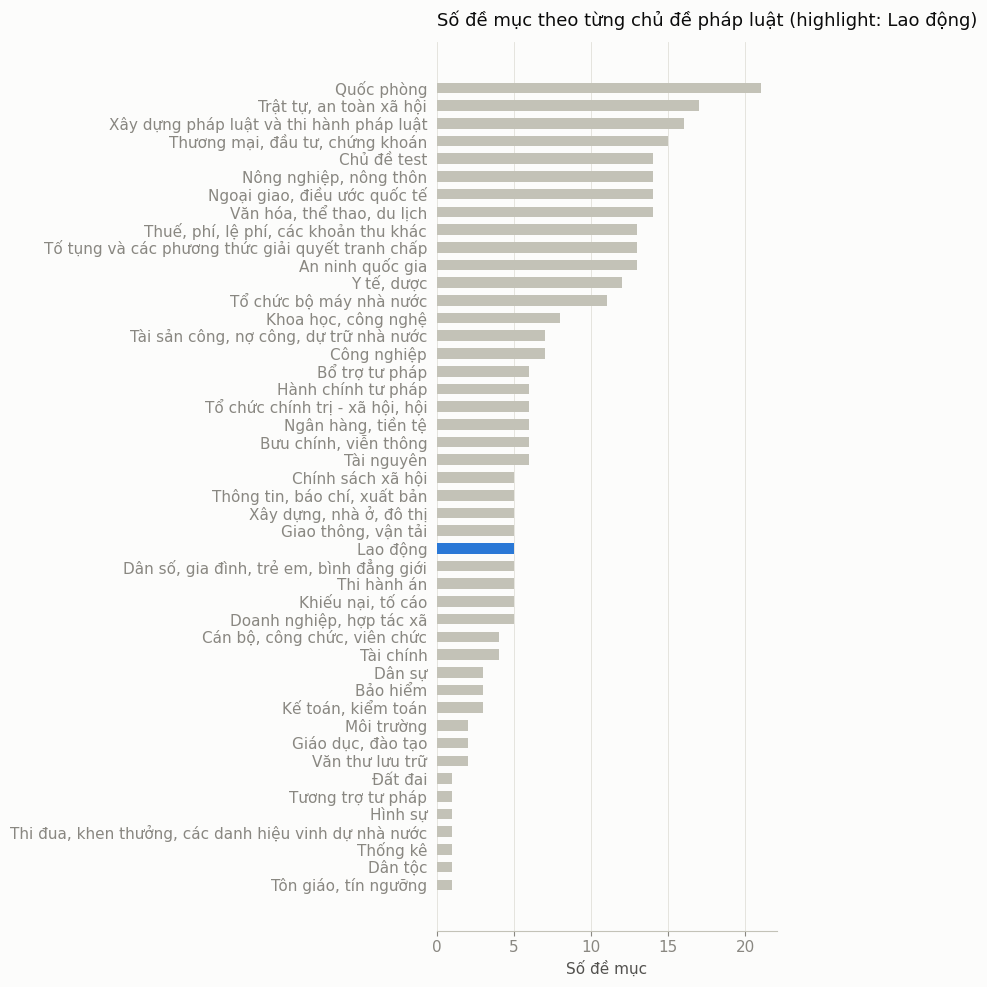

In [3]:
colors = [BLUE if c == "Lao động" else BASELINE for c in df_chude["chu_de"]]
hbar(
    df_chude["chu_de"].tolist(), df_chude["so_de_muc"].tolist(),
    color=colors, figsize=(8, 10),
    title="Số đề mục theo từng chủ đề pháp luật (highlight: Lao động)",
    xlabel="Số đề mục",
)
plt.show()


## 2. Phạm vi dữ liệu chatbot đang dùng (chủ đề "Lao động")

In [4]:
labor_chude_id = next(k for k, v in chu_de.items() if v["Text"] == "Lao động")
labor_demuc = {k: v for k, v in de_muc.items() if v["ChuDe"] == labor_chude_id}

df_labor = pd.DataFrame([
    {"de_muc_id": k, "ten": v["Text"], "stt": v["STT"]}
    for k, v in labor_demuc.items()
]).sort_values("stt").reset_index(drop=True)
df_labor


,de_muc_id,ten,stt
0,985838c2-d5e2-423d-9253-7f95ea82af57,Giáo dục nghề nghiệp,1
1,2efd8c6f-509f-4207-84b6-6b22ff780f2a,Lao động,2
2,70094636-89bd-45c5-90d2-14e1c13e8621,Người lao động Việt Nam đi làm việc ở nước ngo...,3
3,916a0b51-9d2e-4256-be6e-14c2e4b059ae,Việc làm,4
4,b10e4fa0-bfe1-42c1-8ff0-0af74ec834ed,"An toàn, vệ sinh lao động",5


## 3. Cấu trúc phân cấp sau khi parse

Mỗi đề mục được parse thành cây Chương → Mục (tùy chọn) → Điều → Khoản → Điểm (`ingest/parse_demuc_html.py`).

In [5]:
def dieu_list(tree):
    out = list(tree["top_level_dieu"])
    for ch in tree["chuong"]:
        out += ch["dieu"]
        for mc in ch["muc"]:
            out += mc["dieu"]
    return out


rows = []
for path in sorted((DATA_DIR / "parsed").glob("*.json")):
    tree = json.loads(path.read_text(encoding="utf-8"))
    ten = de_muc.get(tree["de_muc_id"], {}).get("Text", tree["de_muc_id"])
    dieu = dieu_list(tree)
    rows.append({
        "de_muc": ten,
        "chuong": len(tree["chuong"]),
        "muc": sum(len(c["muc"]) for c in tree["chuong"]),
        "dieu": len(dieu),
        "khoan": sum(len(d["khoan"]) for d in dieu),
        "diem": sum(len(k["diem"]) for d in dieu for k in d["khoan"]),
        "tham_chieu_cheo": sum(len(d["references"]) for d in dieu),
    })

df_struct = pd.DataFrame(rows).sort_values("dieu", ascending=False).reset_index(drop=True)
df_struct


,de_muc,chuong,muc,dieu,khoan,diem,tham_chieu_cheo
0,Lao động,17,24,477,1596,928,913
1,Việc làm,7,9,393,1228,767,20
2,"An toàn, vệ sinh lao động",7,7,350,811,243,206
3,Người lao động Việt Nam đi làm việc ở nước ngo...,8,9,187,628,445,104
4,Giáo dục nghề nghiệp,0,0,0,0,0,0


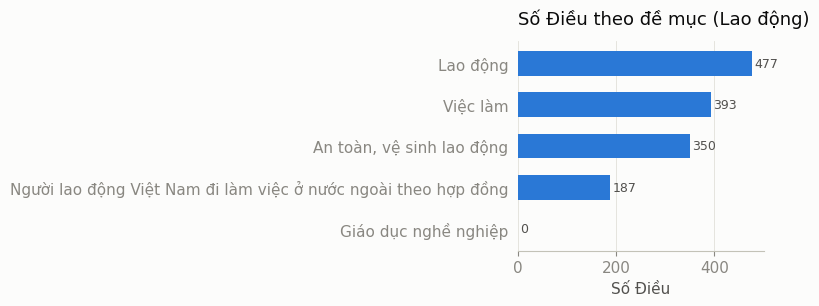

In [6]:
order = df_struct.sort_values("dieu")
hbar(
    order["de_muc"].tolist(), order["dieu"].tolist(),
    figsize=(8, 3.2), title="Số Điều theo đề mục (Lao động)", xlabel="Số Điều",
    value_labels=True,
)
plt.show()


## 4. Dữ liệu chunk dùng để embedding (Qdrant)

`ingest/build_chunks.py` làm phẳng cây đã parse thành `chunks.jsonl` — mỗi chunk = 1 Điều, kèm breadcrumb ngữ cảnh (Đề mục > Chương > Mục).

In [7]:
chunk_lines = (DATA_DIR / "chunks.jsonl").read_text(encoding="utf-8").splitlines()
df_chunks = pd.DataFrame(json.loads(l) for l in chunk_lines if l.strip())
df_chunks["n_chars"] = df_chunks["text"].str.len()
df_chunks["n_words"] = df_chunks["text"].str.split().str.len()

print(f"Tổng số chunk: {len(df_chunks)}")
df_chunks[["n_chars", "n_words", "n_khoan", "n_refs"]].describe().round(1)


Tổng số chunk: 1407


,n_chars,n_words,n_khoan,n_refs
count,1407.0,1407.0,1407.0,1407.0
mean,1272.5,277.3,3.0,0.9
std,1485.0,321.7,2.2,2.0
min,226.0,47.0,1.0,0.0
25%,575.5,124.0,2.0,0.0
50%,900.0,196.0,3.0,0.0
75%,1507.5,331.0,4.0,1.0
max,36261.0,7648.0,36.0,25.0


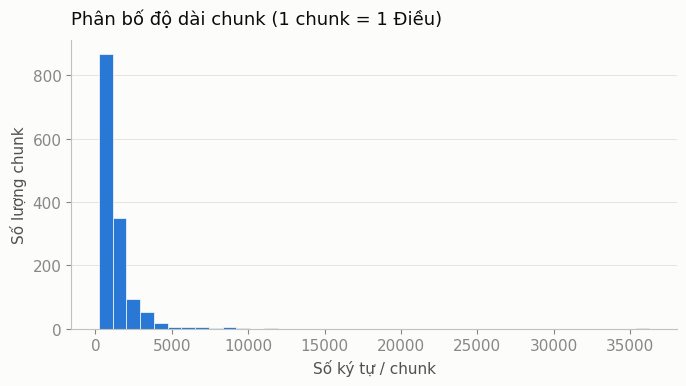

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df_chunks["n_chars"], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set_xlabel("Số ký tự / chunk")
ax.set_ylabel("Số lượng chunk")
ax.set_title("Phân bố độ dài chunk (1 chunk = 1 Điều)", loc="left", color=INK, fontsize=13, pad=12)
ax.grid(axis="y", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


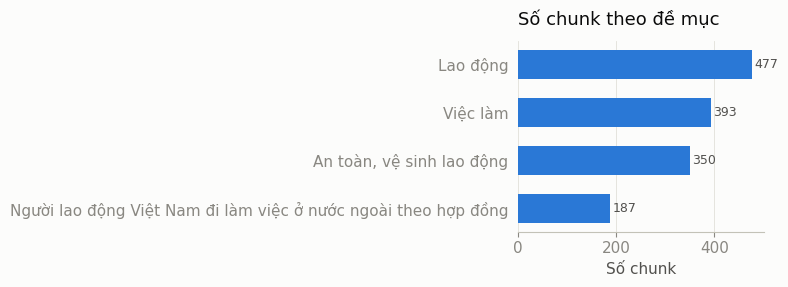

In [9]:
counts = df_chunks["de_muc_id"].value_counts().sort_values()
labels = [de_muc.get(i, {}).get("Text", i) for i in counts.index]
hbar(labels, counts.tolist(), figsize=(8, 3), title="Số chunk theo đề mục", xlabel="Số chunk", value_labels=True)
plt.show()


## 5. Đồ thị tri thức (Knowledge Graph)

`ingest/build_kg.py` dựng node `DeMuc/Chuong/Muc/Dieu` và cạnh `CONTAINS`/`PART_OF`/`REFERS_TO`, nạp vào Neo4j qua `ingest/load_neo4j.py`.

In [10]:
def read_jsonl(path):
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]


df_nodes = pd.DataFrame(read_jsonl(DATA_DIR / "kg_nodes.jsonl"))
df_edges = pd.DataFrame(read_jsonl(DATA_DIR / "kg_edges.jsonl"))

print(f"Tổng số node: {len(df_nodes)}")
print(f"Tổng số cạnh: {len(df_edges)}")
n_stub = (df_nodes["label"].eq("Dieu") & df_nodes["content_available"].eq(False)).sum()
print(f"Trong đó Điều 'stub' (tham chiếu ra ngoài phạm vi đã ingest, chưa có nội dung): {n_stub}")


Tổng số node: 1604
Tổng số cạnh: 4233
Trong đó Điều 'stub' (tham chiếu ra ngoài phạm vi đã ingest, chưa có nội dung): 104


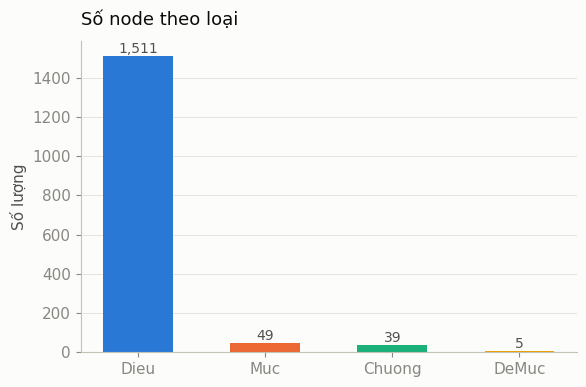

In [11]:
node_counts = df_nodes["label"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(node_counts.index, node_counts.values, color=CAT[:len(node_counts)], width=0.55)
for bar, val in zip(bars, node_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,}",
            ha="center", va="bottom", color=INK_SECOND, fontsize=10)
ax.set_ylabel("Số lượng")
ax.set_title("Số node theo loại", loc="left", color=INK, fontsize=13, pad=12)
ax.grid(axis="y", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


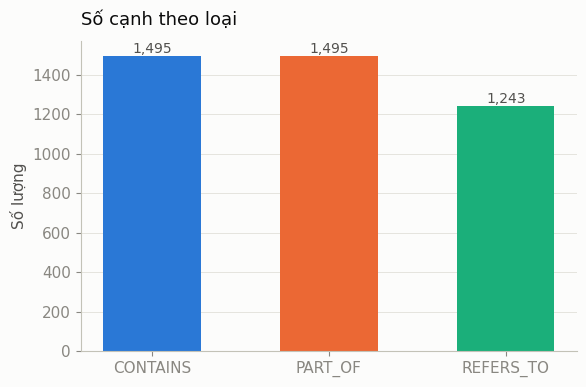

In [12]:
edge_counts = df_edges["type"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(edge_counts.index, edge_counts.values, color=CAT[:len(edge_counts)], width=0.55)
for bar, val in zip(bars, edge_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,}",
            ha="center", va="bottom", color=INK_SECOND, fontsize=10)
ax.set_ylabel("Số lượng")
ax.set_title("Số cạnh theo loại", loc="left", color=INK, fontsize=13, pad=12)
ax.grid(axis="y", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


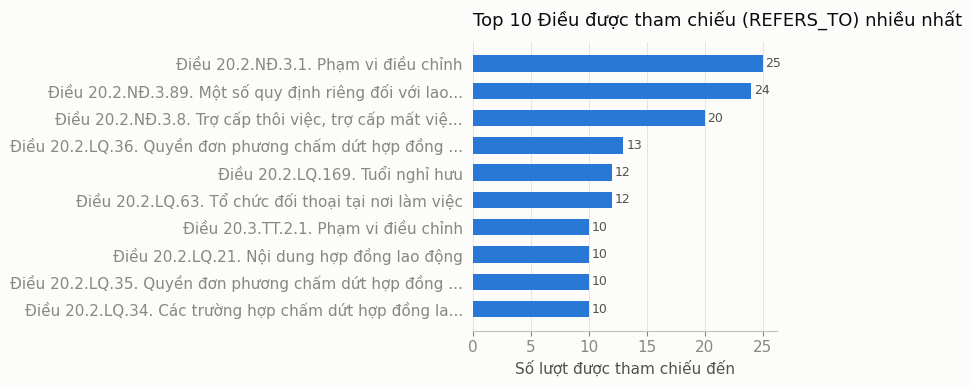

In [13]:
refers = df_edges[df_edges["type"] == "REFERS_TO"]
top_targets = refers["target"].value_counts().head(10).sort_values()
id_to_ten = df_nodes.set_index("id")["ten"].to_dict()
labels = [(id_to_ten.get(i, i) or i) for i in top_targets.index]
labels = [l if len(l) <= 55 else l[:52] + "..." for l in labels]

hbar(labels, top_targets.tolist(), figsize=(8, 4),
     title="Top 10 Điều được tham chiếu (REFERS_TO) nhiều nhất",
     xlabel="Số lượt được tham chiếu đến", value_labels=True)
plt.show()


## 6. Mẫu dữ liệu (để demo)

In [14]:
sample = df_chunks.iloc[df_chunks["n_khoan"].idxmax()]
print(sample["breadcrumb"])
print("-" * 80)
print(sample["text"][:1200])


Đề mục 20.4 - Việc làm > Chương VI BẢO HIỂM THẤT NGHIỆP > Mục 3 TRỢ CẤP THẤT NGHIỆP
--------------------------------------------------------------------------------
Đề mục 20.4 - Việc làm > Chương VI BẢO HIỂM THẤT NGHIỆP > Mục 3 TRỢ CẤP THẤT NGHIỆP
Điều 20.4.TT.3.19. Các mẫu biểu ban hành kèm theo Thông tư
(Điều 19 Thông tư số 28/2015/TT-BLĐTBXH, có hiệu lực thi hành kể từ ngày 15/09/2015)
1. Phiếu tư vấn, giới thiệu việc làm của người lao động thực hiện theo Mẫu số 01.
2. Phiếu giới thiệu việc làm cho người lao động thực hiện theo Mẫu số 02
3. Đề nghị hưởng trợ cấp thất nghiệp của người lao động thực hiện theo Mẫu số 03.
4. Phiếu hẹn trả kết quả của trung tâm dịch vụ việc làm khi người lao động nộp hồ sơ đề nghị hưởng trợ cấp thất nghiệp, hồ sơ đề nghị hỗ trợ học nghề được thực hiện theo Mẫu số 04.
5. Quyết định của Giám đốc Sở Lao động-Thương binh và Xã hội về việc hưởng trợ cấp thất nghiệp thực hiện theo Mẫu số 05.
6. Quyết định của Giám đốc Sở Lao động-Thương binh và Xã hội về việc

## 7. Tóm tắt

In [15]:
print(f"- Tổng số chủ đề trong Bộ Pháp Điển: {len(chu_de)}")
print(f"- Tổng số đề mục trong Bộ Pháp Điển: {len(de_muc)}")
print(f"- Số đề mục thuộc chủ đề Lao động (phạm vi chatbot): {len(df_labor)} / {len(df_labor)}")
print(f"- Tổng số Điều đã parse: {int(df_struct['dieu'].sum())}")
print(f"- Tổng số Khoản: {int(df_struct['khoan'].sum())}")
print(f"- Tổng số Điểm: {int(df_struct['diem'].sum())}")
print(f"- Tổng số tham chiếu chéo (REFERS_TO) trong phạm vi Lao động: {int(df_struct['tham_chieu_cheo'].sum())}")
print(f"- Tổng số chunk đã embedding (Qdrant, collection 'labor_dieu'): {len(df_chunks)}")
print(f"- Tổng số node / cạnh trong Knowledge Graph (Neo4j): {len(df_nodes)} / {len(df_edges)}")


- Tổng số chủ đề trong Bộ Pháp Điển: 46
- Tổng số đề mục trong Bộ Pháp Điển: 320
- Số đề mục thuộc chủ đề Lao động (phạm vi chatbot): 5 / 5
- Tổng số Điều đã parse: 1407
- Tổng số Khoản: 4263
- Tổng số Điểm: 2383
- Tổng số tham chiếu chéo (REFERS_TO) trong phạm vi Lao động: 1243
- Tổng số chunk đã embedding (Qdrant, collection 'labor_dieu'): 1407
- Tổng số node / cạnh trong Knowledge Graph (Neo4j): 1604 / 4233
